# ANN-Based Classification of Depression, Anxiety, and Stress: A Comparative Study with Classical ML and SHAP Interpretability

First, dataset is downloaded and stored in `df`.

In [2]:
import pandas as pd, numpy as np
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lucasgreenwell/depression-anxiety-stress-scales-responses")

print("Path to dataset files:", path)

/Users/mirkodecillis/Library/CloudStorage/GoogleDrive-decillis.web@gmail.com/My Drive/Colab Notebooks/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/mirkodecillis/.cache/kagglehub/datasets/lucasgreenwell/depression-anxiety-stress-scales-responses/versions/1


In [3]:
# path = /root/.cache/kagglehub/datasets/lucasgreenwell/depression-anxiety-stress-scales-responses/versions/1

df = pd.read_csv(f"{path}/data.csv", sep="\t")
print("First 5 records:\n", df.head())
print(df.shape)
df.info()

First 5 records:
    Q1A  Q1I   Q1E  Q2A  Q2I   Q2E  Q3A  Q3I   Q3E  Q4A  ...  screensize  \
0    4   28  3890    4   25  2122    2   16  1944    4  ...           1   
1    4    2  8118    1   36  2890    2   35  4777    3  ...           2   
2    3    7  5784    1   33  4373    4   41  3242    1  ...           2   
3    2   23  5081    3   11  6837    2   37  5521    1  ...           2   
4    2   36  3215    2   13  7731    3    5  4156    4  ...           2   

   uniquenetworklocation  hand  religion  orientation  race  voted  married  \
0                      1     1        12            1    10      2        1   
1                      1     2         7            0    70      2        1   
2                      1     1         4            3    60      1        1   
3                      1     2         4            5    70      2        1   
4                      2     3        10            1    10      2        1   

   familysize       major  
0           2         NaN  


# Data Preparation

Before preprocessing, some columns are already identifiable as removable for the purpose of the analysis. In fact, it is possible to remove the columns regarding how the test was conducted, since they have no predictive value for disease prediction:

- `Q1I`-`Q42I`: item position in the survey
- `Q1E`-`Q42E`: time spent on each question
- `introelapse`,`testelapse`, `surveyelapse`: time spent during the survey
- Technical information regarding the conducted survey: `screensize`, `uniquenetworklocation`, `source`
- Some indicators are definitely not an indicator of depression, anxiety or stress: `engnat`, `hand`, `voted`, `familysize`
- the country where the survey was taken (i.e. `country`) is not relevant to the objective of the analysis

Please refer to the codebook to get more information about the columns.

In [4]:
QxI = [f"Q{i}I" for i in range(1, 43)]
QxE = [f"Q{i}E" for i in range(1, 43)]
cols_to_delete = QxI + QxE + ["introelapse", "testelapse", "surveyelapse",
                        "screensize", "uniquenetworklocation", "source",
                        "engnat", "hand", "country", "familysize", "voted"]

df.drop(columns=cols_to_delete, inplace=True)
print(df.shape)
df.info()

del QxI, QxE, cols_to_delete

(39775, 77)
<class 'pandas.DataFrame'>
RangeIndex: 39775 entries, 0 to 39774
Data columns (total 77 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Q1A          39775 non-null  int64
 1   Q2A          39775 non-null  int64
 2   Q3A          39775 non-null  int64
 3   Q4A          39775 non-null  int64
 4   Q5A          39775 non-null  int64
 5   Q6A          39775 non-null  int64
 6   Q7A          39775 non-null  int64
 7   Q8A          39775 non-null  int64
 8   Q9A          39775 non-null  int64
 9   Q10A         39775 non-null  int64
 10  Q11A         39775 non-null  int64
 11  Q12A         39775 non-null  int64
 12  Q13A         39775 non-null  int64
 13  Q14A         39775 non-null  int64
 14  Q15A         39775 non-null  int64
 15  Q16A         39775 non-null  int64
 16  Q17A         39775 non-null  int64
 17  Q18A         39775 non-null  int64
 18  Q19A         39775 non-null  int64
 19  Q20A         39775 non-null  int64
 20  Q21A 

At this point, it is possible to begin with data cleaning, ensuring that all the values comply to the expected range of values.
Let's start with the answers. There's an issue with the answers of the questionary: in the dataset values, go from 1 to 4. According to Lovibond questionary, values must range from 0 to 3 instead.

In [5]:
columns_answers = [f"Q{i}A" for i in range(1, 43)]

display(df[columns_answers].describe().T[["min", "max"]].T)

if df[columns_answers].min().min() == 1:
    df[columns_answers] -= 1

assert df[columns_answers].min().min() == 0 and df[columns_answers].max().max() == 3

display(df[columns_answers].describe().T[["min", "max"]].T)

,Q1A,Q2A,Q3A,Q4A,Q5A,Q6A,Q7A,Q8A,Q9A,Q10A,...,Q33A,Q34A,Q35A,Q36A,Q37A,Q38A,Q39A,Q40A,Q41A,Q42A
min,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
max,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,...,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0


,Q1A,Q2A,Q3A,Q4A,Q5A,Q6A,Q7A,Q8A,Q9A,Q10A,...,Q33A,Q34A,Q35A,Q36A,Q37A,Q38A,Q39A,Q40A,Q41A,Q42A
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0


Now, an evaluation of the rest of the columns.

In [6]:
def describe_dataset():
  def describe_column(col):
    if col not in df.columns:
      return
    s = df[col]
    desc = s.describe()
    stats = desc[["min", "max"]] if "min" in desc.index else desc

    print(f"### {col} ### dtype: {s.dtype} | non-null: {s.count()}/{len(s)}")
    display(pd.concat([stats, s.value_counts().sort_index(ascending=False).head(10)], axis=1))


  for col in ["age", "gender", "education", "urban", "religion",
              "orientation", "race", "married", "major"]:
    describe_column(col)


  # Ten Item Personality Inventory: rated from 1 to 7
  for i in range(1, 11):
    describe_column(f"TIPI{i}")

  # Validity Check-List: words at VCL6, VCL9, and VCL12 are not real words and can be used as a validity check.
  if "VCL6" in df.columns:
    display(df[["VCL6", "VCL9", "VCL12"]].sum().T)


describe_dataset()

### age ### dtype: int64 | non-null: 39775/39775


,age,count
min,13.0,NaN
max,1998.0,NaN
1998,NaN,1.0
1996,NaN,1.0
1993,NaN,1.0
1991,NaN,1.0
223,NaN,1.0
117,NaN,1.0
115,NaN,1.0
99,NaN,1.0


### gender ### dtype: int64 | non-null: 39775/39775


,gender,count
min,0.0,NaN
max,3.0,NaN
3,NaN,552.0
2,NaN,30367.0
1,NaN,8789.0
0,NaN,67.0


### education ### dtype: int64 | non-null: 39775/39775


,education,count
min,0.0,NaN
max,4.0,NaN
4,NaN,5008.0
3,NaN,15120.0
2,NaN,15066.0
1,NaN,4066.0
0,NaN,515.0


... (29 outputs left out)

,TIPI9,count
min,0.0,NaN
max,7.0,NaN
7,NaN,2591.0
6,NaN,4943.0
5,NaN,6250.0
4,NaN,6837.0
3,NaN,6819.0
2,NaN,6401.0
1,NaN,5507.0
0,NaN,427.0


### TIPI10 ### dtype: int64 | non-null: 39775/39775


,TIPI10,count
min,0.0,NaN
max,7.0,NaN
7,NaN,3494.0
6,NaN,4106.0
5,NaN,6653.0
4,NaN,7665.0
3,NaN,6184.0
2,NaN,5714.0
1,NaN,5404.0
0,NaN,555.0


VCL6     1598
VCL9     1716
VCL12    3352
dtype: int64

Here is what emerged from this step:
- `age` has some issues: sometimes the value inserted is the birth year rather than the age; it'll be fixed estimating the age as the current year is 2018 (average of the period when the data was collected, from 2017 to 2019). It's also worth noting that there are three 3-digits ages (223, 117, 115); for all of them, it appears that those are typos, since the first digit is repeated twice in all cases. Hence, the hundreds digit will be removed from these values;
- in `gender` attribute appears the unexpected value 0; it will be defaulted to 3 "Other";
- in `education` attribute appears the unexpected value 0;, it will be defaulted to the most frequent value. Same criterion will be applied to `urban` attributes;
- unexpected values in `religion` will be defaulted to 12 "Other";
- unexpected values in `orientation` will be defaulted to 5 "Other";
- `race` values are ok;
- unexpected values in `married` will be defaulted to 1 "Never married"
- `TIPI` items with unexpected values will be defaulted to 4 "Neither agree nor disagree";
- for simplicity sake, `major` attribute will not be used anymore; this because mapping these values does not meet the expected return in terms of time spent on cleaning and mapping this attribute.

Before solving all these issues, first we remove the unvalid rows, which are the ones where at least one of the invented words (VCL6 cuivocal, VCL9 florted, VCL12 verdid) is checked. The reason behind that, also supported by the reference report, is that those who check such words is not responding attentively, hence their answers are unreliable.

In [7]:
fake = ["VCL6", "VCL9", "VCL12"]

invalid = (df[fake] == 1).any(axis=1)
print("rows flagged:", invalid.sum(), f"({invalid.mean():.1%})")
print("rows before:", len(df))

df = df.loc[~invalid].reset_index(drop=True)
print("rows after:", len(df))

# VCL columns are no longer needed
df = df.drop(columns=[f"VCL{i}" for i in range(1, 17)], errors="ignore")

rows flagged: 5192 (13.1%)
rows before: 39775
rows after: 34583


And now, values issues are solved.

In [8]:
# AGE
m = df["age"] > 1900
df.loc[m, "age"] = 2018 - df.loc[m, "age"]

m = df["age"] >= 100
df.loc[m, "age"] = df.loc[m, "age"] % 100

# GENDER, RELIGION, ORIENTATION, MARRIED
valid   = {"gender": [1, 2, 3], "religion": range(1, 13),
           "orientation": range(1, 6), "married": [1, 2, 3]}
default = {"gender": 3, "religion": 12, "orientation": 5, "married": 1}
for c in valid:
    df.loc[~df[c].isin(valid[c]), c] = default[c]

# EDUCATION, URBAN
for c, ok in {"education": [1, 2, 3, 4], "urban": [1, 2, 3]}.items():
    mode = df.loc[df[c].isin(ok), c].mode()[0]
    df.loc[~df[c].isin(ok), c] = mode

# TIPI
for c in [f"TIPI{i}" for i in range(1, 11)]:
    df.loc[~df[c].between(1, 7), c] = 4

# DROP MAJOR
df.drop(columns="major", errors="ignore", inplace=True)

# FINAL CHECK: re-execute describe_dataset()
describe_dataset()

### age ### dtype: int64 | non-null: 34583/34583


,age,count
min,13.0,NaN
max,99.0,NaN
99,NaN,1.0
89,NaN,1.0
82,NaN,1.0
80,NaN,4.0
79,NaN,4.0
78,NaN,1.0
77,NaN,4.0
76,NaN,2.0


### gender ### dtype: int64 | non-null: 34583/34583


,gender,count
min,1.0,NaN
max,3.0,NaN
3,NaN,503.0
2,NaN,26680.0
1,NaN,7400.0


### education ### dtype: int64 | non-null: 34583/34583


,education,count
min,1.0,NaN
max,4.0,NaN
4,NaN,4378.0
3,NaN,13799.0
2,NaN,13017.0
1,NaN,3389.0


... (26 outputs left out)

### TIPI9 ### dtype: int64 | non-null: 34583/34583


,TIPI9,count
min,1.0,NaN
max,7.0,NaN
7,NaN,2181.0
6,NaN,4282.0
5,NaN,5494.0
4,NaN,6434.0
3,NaN,5968.0
2,NaN,5576.0
1,NaN,4648.0


### TIPI10 ### dtype: int64 | non-null: 34583/34583


,TIPI10,count
min,1.0,NaN
max,7.0,NaN
7,NaN,3121.0
6,NaN,3731.0
5,NaN,5947.0
4,NaN,7348.0
3,NaN,5349.0
2,NaN,4848.0
1,NaN,4239.0


Another check on nominal columns: rare values, which appear in less than 1% of the rows, should be removed and grouped in the default values. This reduces noise in the dataset, since such infrequent values would not lead to a valuable inference.

In [9]:
nominal_cols = ["gender", "religion", "orientation", "married", "race"]

THRESH = 0.01 # 1% of the dataset

for c in nominal_cols:
    vc = df[c].value_counts(normalize=True)
    vc_under_1pct = vc[vc < THRESH]
    out = pd.DataFrame({"pct": (vc_under_1pct * 100).round(2)}).sort_index()
    print(f"--- {c} ({len(out)} values) ---")
    print(out, "\n")

--- gender (0 values) ---
Empty DataFrame
Columns: [pct]
Index: [] 

--- religion (3 values) ---
           pct
religion      
5         0.26
9         0.32
11        0.14 

--- orientation (0 values) ---
Empty DataFrame
Columns: [pct]
Index: [] 

--- married (0 values) ---
Empty DataFrame
Columns: [pct]
Index: [] 

--- race (3 values) ---
       pct
race      
20    0.82
40    0.04
50    0.49 



Only `race` and `religion` have values under the threshold, to be consolidated. The following values must be consolidated:

| Variable | Value | Meaning |
| -------- | ----- | ------- |
| religion |   5   | Christian (Mormon) |
| religion |   9   | Jewish  |
| religion |   11  |  Sikh   |
|   race   |   20  |  Arab   |
|   race   |   40  | Indigenous Australian |
|   race   |   50  | Native American |

Such values will be consolidated by grouping in their respective "Other" category.

In [10]:
other_code = {"religion": 12, "race": 70}

for c, other in other_code.items():
    freq = df[c].value_counts(normalize=True)
    rare = freq[(freq < THRESH) & (freq.index != other)].index
    print(f"{c}: consolidated {sorted(rare.tolist())} -> {other}")
    df.loc[df[c].isin(rare), c] = other

religion: consolidated [5, 9, 11] -> 12
race: consolidated [20, 40, 50] -> 70


Regarding nominal values, let'use one-hot encoding to represent them. On one side, this will remove the ordinal meaning that could be wrongly attributed to such columns. On the other side, this will increase the number of columns; this will be kept in mind to avoid curse of dimensionality.

In [11]:
print(df.shape)
df = pd.get_dummies(df, columns=nominal_cols, dtype=np.uint8)

print(df.shape)
print(df.dtypes.value_counts())

(34583, 60)
(34583, 79)
int64    55
uint8    24
Name: count, dtype: int64


Next step is creating the labels for each survey. The indexes in `items` are the standard ones of the [DAS-42 handbook](https://upcommons.upc.edu/server/api/core/bitstreams/c357c588-e151-41c0-991e-45dd2f3303a5/content).

Briefly, the answers will be added togheter to get a score for each disease, as described in the following table which uses Lovibond standard thresholds:

| Level            | Depression | Anxiety | Stress |
| ---------------- | ---------- | ------- | ------ |
| Normal           | 0–9  	    | 0–7	    | 0–14   |
| Mild	           | 10–13      | 8–9	    | 15–18  |
| Moderate         | 14–20      | 10–14   | 19–25  |
| Severe           | 21–27      | 15–19   | 26–33  |
| Extremely severe | 28+        | 20+     | 34+    |

`bins` contains the upper limits of each level, starting from -1 because `pd.cut` excludes lower limit.

The final classiffication will be stored in `y`.

In [12]:
DAS_items = {
  "D": [3, 5, 10, 13, 16, 17, 21, 24, 26, 31, 34, 37, 38, 42],
  "A": [2, 4, 7, 9, 15, 19, 20, 23, 25, 28, 30, 36, 40, 41],
  "S": [1, 6, 8, 11, 12, 14, 18, 22, 27, 29, 32, 33, 35, 39],
}
bins = {
  "D": [-1, 9, 13, 20, 27, 42],
  "A": [-1, 7, 9, 14, 19, 42],
  "S": [-1, 14, 18, 25, 33, 42]
}

scores = pd.DataFrame({k: df[[f"Q{i}A" for i in v]].sum(axis=1) for k, v in DAS_items.items()})
y = pd.DataFrame({k: pd.cut(scores[k], bins=bins[k], labels=False) for k in DAS_items})
y.apply(lambda s: s.value_counts().sort_index())

,D,A,S
0,7730,8463,10354
1,3350,2465,4367
2,6232,6260,7608
3,5686,5354,7447
4,11585,12041,4807


# ANN

## Training test and Test set

The dataset will be split into a training set and a test set, with 65/35 ratio. A stratified split will be used because severity classes are imbalanced, so that class proportions are preserved in both partitions.

As each respondent has three simultaneous labels, stratification was applied to the combination of depression, anxiety and stress levels rather than to a single scale, preserving all three distributions jointly.

Validation will be performed via 5-fold cross-validation on the training set.

In [13]:
from sklearn.model_selection import train_test_split

strat = y.astype(str).agg("_".join, axis=1)

idx_train, idx_test = train_test_split(
    df.index, test_size=0.35, stratify=strat, random_state=42
)

for c in y.columns:
    print(pd.concat([y.loc[idx_train, c].value_counts(normalize=True).sort_index(),
                     y.loc[idx_test, c].value_counts(normalize=True).sort_index()],
                    axis=1, keys=["train", "test"]).round(3))

print(f"Training set length: {len(idx_train)}, Test set length: {len(idx_test)}")

   train   test
D              
0  0.224  0.223
1  0.097  0.097
2  0.180  0.180
3  0.164  0.164
4  0.335  0.335
   train   test
A              
0  0.245  0.245
1  0.071  0.071
2  0.181  0.181
3  0.155  0.155
4  0.348  0.348
   train   test
S              
0  0.299  0.300
1  0.126  0.126
2  0.220  0.220
3  0.215  0.215
4  0.139  0.139
Training set length: 22478, Test set length: 12105


Train and test proportions differ by less than 0.1 percentage points.

Now it's time to prepare the data for the ANN:
- create the training and test sets of input and labels
- compute class weights for each disease (D, A, S)

In [14]:
from sklearn.utils.class_weight import compute_class_weight

X_train, X_test = df.loc[idx_train], df.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

class_weights = {}
for col in y_train.columns:
    classes = np.unique(y_train[col])
    weights = compute_class_weight('balanced', classes=classes, y=y_train[col])
    class_weights[col] = dict(zip(classes, weights))

print("Class weights for each scale:")
display(class_weights)

Class weights for each scale:


{'D': {np.int64(0): np.float64(0.8946467661691543),
  np.int64(1): np.float64(2.0650436380339916),
  np.int64(2): np.float64(1.1097506788447298),
  np.int64(3): np.float64(1.2166711772665764),
  np.int64(4): np.float64(0.5970252324037184)},
 'A': {np.int64(0): np.float64(0.8169362166091223),
  np.int64(1): np.float64(2.8062421972534333),
  np.int64(2): np.float64(1.1053848045242194),
  np.int64(3): np.float64(1.2918390804597701),
  np.int64(4): np.float64(0.5744441604906722)},
 'S': {np.int64(0): np.float64(0.6682919577820723),
  np.int64(1): np.float64(1.5829577464788733),
  np.int64(2): np.float64(0.9089365143550344),
  np.int64(3): np.float64(0.9288429752066115),
  np.int64(4): np.float64(1.438592)}}

Before training the neural network, the 42 questionnaire items were standardised and converted into PyTorch tensors. A StandardScaler was fitted on the training set only, so that no information from the test set influenced preprocessing, and features were rescaled to zero mean and unit variance, which stabilises gradient-based optimisation. Features were stored as 32-bit float tensors and the three severity labels as 64-bit integer tensors, the formats required by PyTorch layers and the cross-entropy loss. Tensors support automatic differentiation, enabling backpropagation. Finally, data were wrapped in a DataLoader that feeds shuffled mini-batches of 512 samples, making training efficient and less prone to overfitting.

## Classifier and methods to train and test it

The classifier is a small multi-output feed-forward neural network implemented in PyTorch. A shared trunk, made of two fully connected layers with 64 and 32 units, ReLU activations and dropout (p = 0.2), learns a common representation of the questionnaire items.

Three independent linear heads, one per DASS subscale, map this representation to the five severity classes. Sharing the trunk exploits the strong correlation between depression, anxiety and stress, while separate heads allow scale-specific decisions.

The network outputs raw logits, and the total loss is the sum of three class-weighted cross-entropy terms, one per scale.

In [15]:
import torch
import torch.nn as nn

class MultiHeadANN(nn.Module):
    def __init__(self, n_features, hidden1=64, hidden2=32, n_classes=5, dropout=0.2):
        super().__init__()
        # shared trunk
        self.trunk = nn.Sequential(
            nn.Linear(n_features, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
        )
        # one head per scale (D, A, S)
        self.head_D = nn.Linear(hidden2, n_classes)
        self.head_A = nn.Linear(hidden2, n_classes)
        self.head_S = nn.Linear(hidden2, n_classes)

    def forward(self, x):
        h = self.trunk(x)
        return self.head_D(h), self.head_A(h), self.head_S(h)  # logits, no softmax

Training is implemented with three functions:
- `run_epoch` iterates over mini-batches: the model processes each batch as a matrix, the three class-weighted cross-entropy losses are summed, and backpropagation computes the gradients that the Adam optimiser, bound to the model parameters, uses to update them; in evaluation mode dropout and gradient tracking are disabled
- `fit` repeats epochs with early stopping on validation loss and restores the best weights
- `evaluate` returns accuracy and macro- and weighted-F1 per scale.

In [16]:
import copy
from sklearn.metrics import f1_score

SCALES = ["D", "A", "S"]

# one weighted loss per scale (weights computed on the train set)
w = {c: torch.tensor([class_weights[c][k] for k in range(5)], dtype=torch.float32) for c in SCALES}
criteria = [nn.CrossEntropyLoss(weight=w[c]) for c in SCALES]

def run_epoch(model, loader, optimizer=None):
    """One pass over the loader. Trains if an optimizer is given, otherwise only evaluates the loss."""
    training = optimizer is not None
    model.train(training)                      # enables/disables dropout
    total, n = 0.0, 0
    with torch.set_grad_enabled(training):     # no gradients during validation
        for xb, yb in loader:
            outs = model(xb)                   # (logits_D, logits_A, logits_S)
            loss = sum(crit(o, yb[:, i]) for i, (crit, o) in enumerate(zip(criteria, outs)))
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(xb)
            n += len(xb)
    return total / n

def fit(model, train_loader, val_loader, epochs=200, lr=3e-3, patience=10):
    """Adam + early stopping on validation loss; restores the best weights."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, best_state, wait, history = float("inf"), None, 0, []
    for ep in range(epochs):
        tr, va = run_epoch(model, train_loader, opt), run_epoch(model, val_loader)
        history.append((tr, va))
        if va < best - 1e-3:
            best, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history

@torch.no_grad()
def evaluate(model, X, y):
    """Accuracy and macro/weighted F1 for each scale."""
    model.eval()
    res = {}
    for i, (c, logits) in enumerate(zip(SCALES, model(X))):
        pred, true = logits.argmax(1).numpy(), y[:, i].numpy()
        res[c] = {
          "pred": pred,
          "true": true,
          "acc": (pred == true).mean(),
          "f1_macro": f1_score(true, pred, average="macro"),
          "f1_weighted": f1_score(true, pred, average="weighted")
        }
    return res

To estimate performance reliably, the network was evaluated with stratified 5-fold cross-validation on the training set. In each fold, a StandardScaler was fitted on the training portion only, a new network was initialised, trained with early stopping on the held-out fold, and scored on accuracy, macro-F1 and weighted-F1 for each scale. Stratification used the anxiety label. Averaging over folds gives a mean and a standard deviation for each metric, which is essential here because differences between models are expected to be a fraction of a percentage point. The test set remains untouched until the final evaluation.

In [17]:
import time
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold

def run_cv(X, y, strat_labels, n_splits=5, seed=42, **fit_kwargs):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr_i, va_i) in enumerate(skf.split(X, strat_labels), 1):
        scaler = StandardScaler().fit(X[tr_i])                       # fit on training fold only
        Xt = torch.tensor(scaler.transform(X[tr_i]), dtype=torch.float32)
        Xv = torch.tensor(scaler.transform(X[va_i]), dtype=torch.float32)
        yt = torch.tensor(y[tr_i], dtype=torch.long)
        yv = torch.tensor(y[va_i], dtype=torch.long)

        tl = DataLoader(TensorDataset(Xt, yt), batch_size=512, shuffle=True)
        vl = DataLoader(TensorDataset(Xv, yv), batch_size=512)

        torch.manual_seed(seed + fold)                               # reproducible init
        model = MultiHeadANN(n_features=X.shape[1])                  # fresh model per fold
        model, hist = fit(model, tl, vl, **fit_kwargs)
        res = evaluate(model, Xv, yv)
        for c in SCALES:
            rows.append({"fold": fold, "scale": c, "epochs": len(hist), **res[c]})
        print(f"fold {fold} done")
    return pd.DataFrame(rows)

Finally, here's the method to train the final model to use against the test set.

In [18]:
from sklearn.metrics import confusion_matrix, classification_report

def train_final(X_tr_df, y_tr, X_te_df, y_te, strat_labels, seed=42, val_size=0.10):
    """Train one final model on the training set and evaluate it once on the test set."""
    # 1) hold out a stratified validation slice of the TRAIN set, for early stopping only
    tr_i, va_i = train_test_split(np.arange(len(X_tr_df)), test_size=val_size,
                                  random_state=seed, stratify=strat_labels)
    Xtr_, Xva_ = X_tr_df.values[tr_i], X_tr_df.values[va_i]

    # 2) scaler fitted on the remaining training rows only
    scaler = StandardScaler().fit(Xtr_)
    T = lambda a: torch.tensor(scaler.transform(a), dtype=torch.float32)
    Y = lambda a: torch.tensor(a, dtype=torch.long)
    Xt, Xv, Xte = T(Xtr_), T(Xva_), T(X_te_df.values)
    yt, yv, yte = Y(y_tr[tr_i]), Y(y_tr[va_i]), Y(y_te)

    tl = DataLoader(TensorDataset(Xt, yt), batch_size=512, shuffle=True)
    vl = DataLoader(TensorDataset(Xv, yv), batch_size=512)

    # 3) fresh model, training with early stopping on the validation slice
    torch.manual_seed(seed)
    model = MultiHeadANN(n_features=Xt.shape[1])
    model, hist = fit(model, tl, vl)

    # 4) single evaluation on the test set
    return model, hist, evaluate(model, Xte, yte), Xte, yte, Xt, yt


def results_table(res, keys=("acc", "f1_macro", "f1_weighted")):
    return pd.DataFrame({c: {k: res[c][k]*100 for k in keys} for c in res}).T.round(4)

## Experiment A

Let's start with Experiment A. In this case, the model is trained using only the answers to the questionnaire. Later, in Experiment B, the model will be trained using all the information provided by the dataset after the clearing step (i.e. answers + TIPI + demographics). The goal is to verify whether removing this information leaves performance unchanged, using the same metrics (e.g. accuracy, F1-score), thus assessing whether those features are actually necessary.

The model in experiment A should be accurate because of the way the labels are built: the labels are deterministically derived from the questionnaire answers (the sum of the relevant items per scale, mapped to the standard severity thresholds). Since the target is a function of the very features the model receives, Experiment A is essentially learning a known rule, and it should reach near-perfect precision. In Experiment B, the additional variables (TIPI scores and demographics) are not involved in the label definition, so they can only add noise or redundancy. Therefore, B is expected to perform at most as well as A.

In [19]:
print("A) 5-fold cross-validation on the training set")

t0 = time.time()
cv_A = run_cv(X_train[columns_answers].values, y_train[SCALES].values, y_train["A"].values)
print(f"{time.time() - t0:.0f}s")

cv_A.groupby("scale")[["acc", "f1_macro", "f1_weighted"]].agg(["mean", "std"]).round(4)

A) 5-fold cross-validation on the training set
fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done
31s


acc         f1_macro         f1_weighted        
         mean     std     mean     std        mean     std
scale                                                     
A      0.9999  0.0002   0.9998  0.0004      0.9999  0.0002
D      0.9957  0.0056   0.9941  0.0076      0.9957  0.0056
S      0.9972  0.0029   0.9967  0.0034      0.9972  0.0029

In [20]:
print("A) Final model evaluation on the test set")
model_A, hist_A, res_A, Xte_A, yte_A, Xt_A, yt_A = train_final(
    X_train[columns_answers], y_train[SCALES].values,
    X_test[columns_answers], y_test[SCALES].values,
    strat_labels=y_train["A"].values)

print(len(hist_A))
print(results_table(res_A))

for c in SCALES:
    pred, true = res_A.get(c).get("pred"), res_A.get(c).get("true")
    print(c); print(confusion_matrix(true, pred))
    print(classification_report(true, pred, digits=4))

A) Final model evaluation on the test set
63
        acc  f1_macro  f1_weighted
D   98.6204   98.2019      98.6345
A  100.0000  100.0000     100.0000
S   99.6943   99.6374      99.6943
D
[[2584  121    0    0    0]
 [   0 1170    3    0    0]
 [   0    0 2181    0    0]
 [   0    0    0 1991    0]
 [   0    0    0   43 4012]]
              precision    recall  f1-score   support

           0     1.0000    0.9553    0.9771      2705
           1     0.9063    0.9974    0.9497      1173
           2     0.9986    1.0000    0.9993      2181
           3     0.9789    1.0000    0.9893      1991
           4     1.0000    0.9894    0.9947      4055

    accuracy                         0.9862     12105
   macro avg     0.9768    0.9884    0.9820     12105
weighted avg     0.9872    0.9862    0.9863     12105

A
[[2960    0    0    0    0]
 [   0  863    0    0    0]
 [   0    0 2193    0    0]
 [   0    0    0 1874    0]
 [   0    0    0    0 4215]]
              precision    recall  f1-sc

Results are very promising, with accuracy close to 100%. The model only has to approximate a deterministic rule (sum of items mapped to fixed thresholds). This is therefore not true prediction, but a recovery of the labeling function, which explains the almost perfect scores.

## Experiment B and comparison with A

Now, let's do the same for Experiment B.

In [21]:
print("B) 5-fold cross-validation on the training set")
t0 = time.time()
cv_B = run_cv(X_train.values, y_train[SCALES].values, y_train["A"].values)
print(f"{time.time() - t0:.0f}s")

cv_B.groupby("scale")[["acc", "f1_macro", "f1_weighted"]].agg(["mean", "std"]).round(4)

B) 5-fold cross-validation on the training set
fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done
33s


acc         f1_macro         f1_weighted        
         mean     std     mean     std        mean     std
scale                                                     
A      0.9975  0.0022   0.9956  0.0039      0.9975  0.0021
D      0.9913  0.0051   0.9884  0.0063      0.9914  0.0050
S      0.9851  0.0121   0.9832  0.0133      0.9852  0.0119

In [22]:
print("B) Final model evaluation on the test set")
model_B, hist_B, res_B, Xte_B, yte_B, Xt_B, yt_B = train_final(
    X_train, y_train[SCALES].values,
    X_test, y_test[SCALES].values,
    strat_labels=y_train["A"].values)

print(len(hist_B))
print(results_table(res_B))

for c in SCALES:
    pred, true = res_B.get(c).get("pred"), res_B.get(c).get("true")
    print(confusion_matrix(true, pred))
    print(classification_report(true, pred, digits=4))

B) Final model evaluation on the test set
108
       acc  f1_macro  f1_weighted
D  99.4630   99.4035      99.4638
A  99.8843   99.8063      99.8846
S  99.5787   99.5056      99.5792
D
[[2696    9    0    0    0]
 [  14 1159    0    0    0]
 [   0    0 2181    0    0]
 [   0    0    1 1990    0]
 [   0    0    0   41 4014]]
              precision    recall  f1-score   support

           0     0.9948    0.9967    0.9958      2705
           1     0.9923    0.9881    0.9902      1173
           2     0.9995    1.0000    0.9998      2181
           3     0.9798    0.9995    0.9896      1991
           4     1.0000    0.9899    0.9949      4055

    accuracy                         0.9946     12105
   macro avg     0.9933    0.9948    0.9940     12105
weighted avg     0.9947    0.9946    0.9946     12105

A
[[2951    9    0    0    0]
 [   0  863    0    0    0]
 [   0    2 2191    0    0]
 [   0    0    2 1872    0]
 [   0    0    0    1 4214]]
              precision    recall  f1-score

Both experiments reach near-perfect performance on all three scales. Adding TIPI and demographic features does not yield a consistent gain: B is slightly better on Depression, A on Anxiety and Stress. All misclassifications occur between adjacent severity classes, close to the score thresholds that define the labels. This confirms that the questionnaire answers alone carry the information needed to recover the labeling function.

# SHAP

Now it's time to evaluate which features the ANN actually relies on to classify depression, anxiety and stress, and in particular whether the TIPI and demographic variables carry any information beyond the 42 questionnaire items. Such evaluation will be carried using the SHAP method.

SHAP (SHapley Additive exPlanations) is a game-theoretic method that assigns each feature a contribution to a single prediction, such that the model output equals a baseline value (the average output on a background sample) plus the sum of all feature contributions. Averaging the absolute contributions over many samples gives a global importance measure, while their sign and magnitude on individual samples give local explanations.

The analysis has two parts: the mean |SHAP| averaged over the 5 severity classes gives a global importance ranking per scale, while the SHAP values of a single class show which input values push the prediction towards or away from that specific severity label.

Since the model has a single shared trunk and three output heads (D, A, S), and `DeepExplainer` explains one output at a time, we wrap each head in a small `nn.Module` so that every scale is explained separately.

In [23]:
import shap

SCALES_ENUM = list(enumerate(SCALES))

class HeadWrapper(nn.Module):
    """Expose a single head (0=D, 1=A, 2=S) as a model with one output of 5 logits."""
    def __init__(self, model, h):
        super().__init__()
        self.model, self.h = model, h
    def forward(self, x):
        return self.model(x)[self.h]

In [24]:
model_A.eval()
torch.manual_seed(0)
idx_bg_A = torch.randperm(len(Xt_A))[:100]
background_A = Xt_A[idx_bg_A]
idx_test_A = torch.randperm(len(Xte_A))[:3000]
sub_test_A = Xte_A[idx_test_A]

shap_A = {}
for h, c in SCALES_ENUM:
    explainer = shap.DeepExplainer(HeadWrapper(model_A, h), background_A)
    shap_A[c] = explainer.shap_values(sub_test_A)
    print(c, type(shap_A[c]), np.shape(shap_A[c]))

D <class 'numpy.ndarray'> (3000, 42, 5)
A <class 'numpy.ndarray'> (3000, 42, 5)
S <class 'numpy.ndarray'> (3000, 42, 5)


In [25]:
model_B.eval()
torch.manual_seed(0)
idx_bg_B = torch.randperm(len(Xt_B))[:100]
background_B = Xt_B[idx_bg_B]
idx_test_B = torch.randperm(len(Xte_B))[:3000]
sub_test_B = Xte_B[idx_test_B]

shap_B = {}
for h, c in SCALES_ENUM:
    explainer = shap.DeepExplainer(HeadWrapper(model_B, h), background_B)
    shap_B[c] = explainer.shap_values(sub_test_B)
    print(c, type(shap_B[c]), np.shape(shap_B[c]))

D <class 'numpy.ndarray'> (3000, 79, 5)
A <class 'numpy.ndarray'> (3000, 79, 5)
S <class 'numpy.ndarray'> (3000, 79, 5)


For each scale and each experiment will be checked:
 - additivity: the model logits must equal the baseline (mean output on the background sample) plus the sum of the SHAP values over features;
  - stability: the importance ranking computed on the first and on the second half of the 3,000-row test subsample must agree (Spearman correlation).

In [26]:
from scipy.stats import spearmanr

def check(model, sv, background, sub_test):
    model.eval()
    for h, c in SCALES_ENUM:
        w = HeadWrapper(model, h)
        with torch.no_grad():
            logits = w(sub_test).numpy()                    # (3000, 5)
            base = w(background).mean(0).numpy()            # (5,)
        err = np.abs(logits - (base + sv[c].sum(axis=1))).max()
        imp = np.abs(sv[c]).mean(axis=2)                    # (3000, f)
        half = len(imp) // 2
        rho = spearmanr(imp[:half].mean(0), imp[half:].mean(0)).correlation
        print(f"{c}: max recon error {err:.2e} | Spearman halves {rho:.3f}")

check(model_A, shap_A, background_A, sub_test_A)
check(model_B, shap_B, background_B, sub_test_B)

D: max recon error 3.29e-05 | Spearman halves 0.997
A: max recon error 3.06e-05 | Spearman halves 0.998
S: max recon error 5.81e-05 | Spearman halves 0.996
D: max recon error 6.09e-05 | Spearman halves 0.997
A: max recon error 7.47e-05 | Spearman halves 0.998
S: max recon error 6.12e-05 | Spearman halves 0.998


The maximum reconstruction error is below 1e-4 for all scales in both experiments, so SHAP values are an exact decomposition of the logits. The Spearman correlation between the two halves is 0.996-0.998, so 3,000 samples are enough for a stable ranking.

Now let's compute the importance of each variables group (own-scale items, other-scale items, TIPI, demographics). `importance` sums the SHAP values of a variable's dummies for each sample and class, takes the absolute value, averages over samples and classes, and normalises to 100% per scale. Results are stored in `imp_A` and `imp_B`.

In [27]:
import re

def var_of(c):
    """gender_1 -> gender; Q12A, TIPI3, age unchanged"""
    return c.rsplit("_", 1)[0] if "_" in c else c


def group_of(v, scale):
    if v.startswith("Q") and v.endswith("A"):
        m = re.search(r"Q(\d+)A", v)
        assert m is not None
        x = int(m.group(1))
        return "own items" if x in DAS_items[scale] else "other items"
    return "TIPI" if v.startswith("TIPI") else "demographics"

def importance(sv_dict, cols):
    """Per scale: mean over samples and classes of |sum of the SHAP of a variable's dummies|."""
    vars_ = np.array([var_of(c) for c in cols])
    out = {}
    for c, sv in sv_dict.items():                           # sv: (n, f, 5)
        s = pd.Series({v: np.abs(sv[:, vars_ == v, :].sum(axis=1)).mean()
                            for v in dict.fromkeys(vars_)})
        out[c] = s / s.sum() * 100
    return pd.DataFrame(out)

imp_A = importance(shap_A, columns_answers)
imp_B = importance(shap_B, X_train.columns)

Once computed, the importances are aggregated by group, either summing it (share of the scale's importance carried by the group) or averaging it (importance of a single variable of the group, which corrects for group size).

In [28]:
def group_summary(imp, agg="sum"):
    out = {}
    for c in imp.columns:
        g = pd.Series({v: group_of(v, c) for v in imp.index})
        s = imp[c].groupby(g).agg(agg)
        out[c] = s / s.sum() * 100 if agg == "sum" else s        # shares for "sum", raw mean per variable for "mean"
    df = pd.DataFrame(out).T
    return df[[g for g in ["own items", "other items", "TIPI", "demographics"] if g in df.columns]]

display("Importance A (sum)", group_summary(imp_A).round(3))     # A: only items, so TIPI/demographics will not exist -> drop those columns
display("Importance B (sum)", group_summary(imp_B, "sum").round(2))
display("Importance B (mean)", group_summary(imp_B, "mean").round(2))   # per-variable mean: corrects for group size

'Importance A (sum)'

,own items,other items
D,84.074,15.926
A,81.244,18.756
S,87.636,12.364


'Importance B (sum)'

,own items,other items,TIPI,demographics
D,79.12,12.67,0.97,7.23
A,83.23,8.93,0.83,7.00
S,77.50,14.49,0.94,7.07


'Importance B (mean)'

,own items,other items,TIPI,demographics
D,5.65,0.45,0.10,0.90
A,5.95,0.32,0.08,0.88
S,5.54,0.52,0.09,0.88


In Experiment A, own-scale items carry 84 / 81 / 88% of the importance (D / A / S). In Experiment B they carry 79 / 83 / 78%, other-scale items 9-14%, TIPI about 1% and demographics about 7%. Per variable, an own item weighs about 5.5-6%, an other-scale item 0.3-0.5%, a TIPI item 0.1% and a demographic variable about 0.9%: a single demographic variable matters two to three times more than a single other-scale item, but far less than an own item.

In both cases, let's see, for each scale, the five variables with the highest importance among those that are not items of the scale itself, with their group, for Experiment A and B.

In [29]:
def top_non_own(imp, scale, k=5):
    g = pd.Series({v: group_of(v, scale) for v in imp.index})
    s = imp.loc[g != "own items", scale].sort_values(ascending=False)
    return pd.DataFrame({
        "group": g[s.index],
        "% of total": s,
    }).head(k)

print("A) Top non-own features")
for sc in imp_A.columns:
    print(f"--- {sc} ---")
    display(top_non_own(imp_A, sc).round(2))

print("B) Top non-own features")
for sc in imp_B.columns:
    print(f"--- {sc} ---")
    display(top_non_own(imp_B, sc).round(2))


A) Top non-own features
--- D ---


,group,% of total
Q40A,other items,0.95
Q30A,other items,0.93
Q20A,other items,0.90
Q9A,other items,0.89
Q28A,other items,0.88


--- A ---


,group,% of total
Q17A,other items,1.21
Q21A,other items,1.21
Q10A,other items,1.14
Q34A,other items,1.13
Q37A,other items,1.12


--- S ---


,group,% of total
Q9A,other items,0.66
Q36A,other items,0.63
Q40A,other items,0.62
Q30A,other items,0.60
Q28A,other items,0.60


... (2 outputs left out)

--- A ---


,group,% of total
religion,demographics,3.34
race,demographics,1.43
married,demographics,0.95
gender,demographics,0.64
orientation,demographics,0.46


--- S ---


,group,% of total
religion,demographics,2.50
race,demographics,1.78
married,demographics,1.74
Q2A,other items,0.67
Q20A,other items,0.67


In A, even the top non-own features are totally irrilevant (about 0.9-1.2% each). In B, demographics take the top positions: `religion` is first on all scales (3.09 / 3.34 / 2.50%), followed by race, marital status and gender (about 0.4-1.8%), while the best other-scale item reaches only 0.5-0.7% (Q14A for D, Q2A and Q20A for S). TIPI variables do not appear in the top five.

In B, `religion` appears to be somehow a little bit relevant in determining depression, anxiety and stress. Let's dig deeper in this hypothesis, limiting the analysis to Depression head. In the following block of code, sums the SHAP values of the `religion` dummies, centres them over the five classes and averages them for each religion (identified from the dummies of the test subsample). The table shows how much `religion` pushes the logit of each severity class up (positive) or down (negative), together with the number of respondents `n`.

**Results.** Muslim respondents (n = 1,739) are pushed away from "normal" (-3.57) and towards moderate and severe (+1.03, +1.54). Most other groups show the opposite pattern (e.g. Agnostic +8.29 and Hindu +9.05 on "normal"), and Catholic is close to neutral. The groups with n < 100 (Buddhist 34, Hindu 60) are too small to be interpreted.

In [59]:
REL_NAMES = {"religion_1": "Agnostic", "religion_2": "Atheist", "religion_3": "Buddhist",
             "religion_4": "Catholic", "religion_6": "Protestant", "religion_7": "Other Christian",
             "religion_8": "Hindu", "religion_10": "Muslim", "religion_12": "Other"}

shap_b_d = shap_B["D"]
cols = list(X_train.columns)
rel_idx = [i for i, c in enumerate(cols) if c.startswith("religion_")]

sv_rel = shap_b_d[:, rel_idx, :].sum(axis=1)
sv_rel = sv_rel - sv_rel.mean(axis=1, keepdims=True)

sub_test_B_array = np.asarray(sub_test_B)
rel_names = np.array([cols[i] for i in rel_idx])
rel_name = rel_names[sub_test_B_array[:, rel_idx].argmax(axis=1)]

LEVELS = ["normal", "mild", "moderate", "severe", "ext. severe"]
rel_name = np.array([REL_NAMES.get(n, n) for n in rel_name])

res = pd.DataFrame(sv_rel, columns=LEVELS).groupby(rel_name).mean()
res["n"] = pd.Series(rel_name).value_counts()
print(res.round(2))

                  normal     mild  moderate   severe  ext. severe     n
Agnostic         8.29000  0.01000  -1.94000 -3.25000     -3.11000   212
Atheist          3.68000 -0.59000  -1.52000 -2.10000      0.53000   256
Buddhist        -1.59000  0.15000   1.51000  0.65000     -0.71000    34
Catholic         0.33000 -0.09000   0.11000  0.22000     -0.56000   246
Hindu            9.05000 -0.13000  -2.31000 -2.90000     -3.70000    60
Muslim          -3.57000  0.19000   1.03000  1.54000      0.81000  1739
Other            6.87000 -0.63000  -2.63000 -3.33000     -0.28000   178
Other Christian  4.13000 -0.16000  -1.47000 -2.88000      0.38000   173
Protestant       4.39000 -0.13000  -1.01000 -1.31000     -1.94000   102


Muslim respondents (n = 1,739) are pushed away from "normal" (-3.57) and towards moderate and severe (+1.03, +1.54). Most other groups show the opposite pattern (e.g. Agnostic +8.29 and Hindu +9.05 on "normal"), and Catholic is close to neutral. The groups with n < 100 (Buddhist 34, Hindu 60) are too small to be interpreted.

Since Muslim respondents make up 58% of the sample, the SHAP attributions for religion mainly reflect a Muslim vs. non-Muslim contrast relative to a Muslim-dominated background; estimates for the other categories rest on small subsamples and should not be generalized.

# Charts and graphs

First, a general setup for this section (color palette, constants. figures will be saved in `/figures` as PDF and PNG.

In [39]:
import os
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix

os.makedirs("figures", exist_ok=True)

mpl.rcParams.update({
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "legend.fontsize": 7, "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
})

GROUPS = ["own items", "other items", "TIPI", "demographics"]
GROUP_COLORS = {"own items": "#0072B2", "other items": "#56B4E9",
                "TIPI": "#E69F00", "demographics": "#D55E00"}
SCALE_NAMES = {"D": "Depression", "A": "Anxiety", "S": "Stress"}
LEVELS = ["normal", "mild", "moderate", "severe", "ext. severe"]
CLASS_SHORT = ["N", "Mi", "Mo", "Se", "ES"]

def save_fig(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", bbox_inches="tight")

Fig. 1: Learning curves

Training and validation loss (sum of the three class-weighted cross-entropies) per epoch for the final models of Experiments A and B. Two side-by-side panels share a logarithmic y-axis. Each shows the train and validation curves and a dashed vertical line at the epoch of minimum validation loss, where early stopping restores the weights.

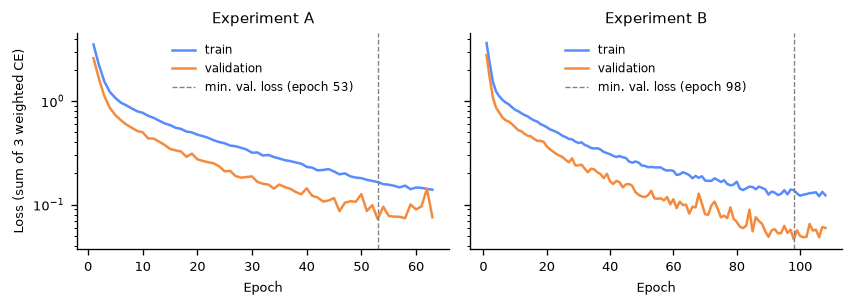

In [40]:
def plot_learning_curves(hists, titles=("Experiment A", "Experiment B")):
    fig, axes = plt.subplots(1, len(hists), figsize=(7.16, 2.6), sharey=True)
    for ax, h, t in zip(axes, hists, titles):
        h = np.asarray(h)                                  # (epochs, 2) = (train, val)
        ep = np.arange(1, len(h) + 1)
        best = int(h[:, 1].argmin()) + 1
        ax.plot(ep, h[:, 0], label="train")
        ax.plot(ep, h[:, 1], label="validation")
        ax.axvline(best, ls="--", c="gray", lw=0.8, label=f"min. val. loss (epoch {best})")
        ax.set_yscale("log")
        ax.set_xlabel("Epoch")
        ax.set_title(t)
        ax.legend(frameon=False)
    axes[0].set_ylabel("Loss (sum of 3 weighted CE)")
    fig.tight_layout()
    return fig

fig = plot_learning_curves([hist_A, hist_B])
save_fig(fig, "fig1_learning_curves")
plt.show()

Fig. 2: Confusion matrices

Test-set confusion matrices (12,105 samples) for Experiments A and B on each scale. The 2×3 grid has experiments as rows and Depression, Anxiety and Stress as columns. Each 5×5 matrix compares true and predicted severity class: cell numbers are counts, colour shows the row-normalised proportion. Errors occur only between adjacent classes.

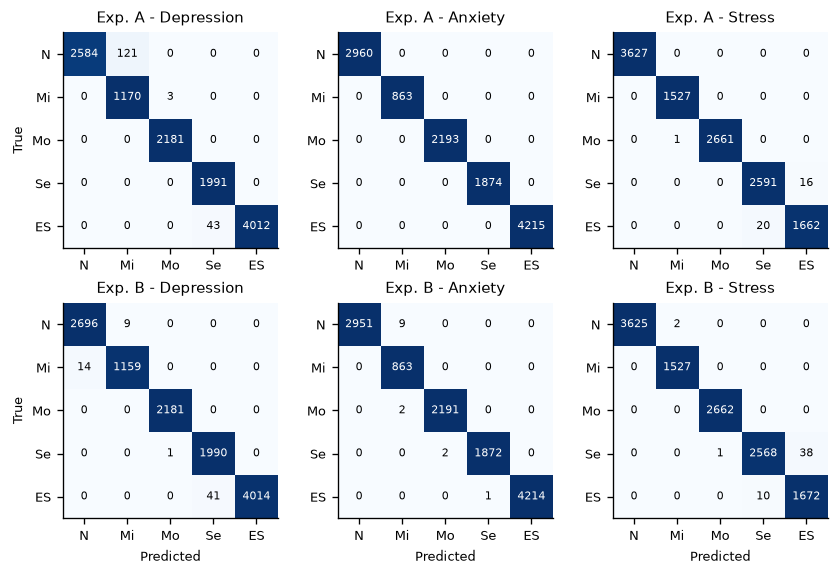

In [41]:
def plot_confusion(results, names=("A", "B")):
    fig, axes = plt.subplots(len(results), 3, figsize=(7.16, 2.4 * len(results)))
    for r, (res_, name) in enumerate(zip(results, names)):
        for c, sc in enumerate(SCALES):
            ax = axes[r, c]
            cm = confusion_matrix(res_[sc]["true"], res_[sc]["pred"], labels=list(range(5)))
            norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)       # row-normalised
            ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
            for i in range(5):
                for j in range(5):
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5,
                            color="white" if norm[i, j] > 0.5 else "black")
            ax.set_xticks(range(5), CLASS_SHORT)
            ax.set_yticks(range(5), CLASS_SHORT)
            ax.set_title(f"Exp. {name} - {SCALE_NAMES[sc]}")
            if r == len(results) - 1: ax.set_xlabel("Predicted")
            if c == 0: ax.set_ylabel("True")
    fig.tight_layout()
    return fig

fig = plot_confusion([res_A, res_B])
save_fig(fig, "fig2_confusion")
plt.show()

Fig. 3: Importance by variable group

Share of total mean |SHAP| attributed to four variable groups: own-scale items, other-scale items, TIPI and demographics. Stacked bars sum to 100% for each scale, with Experiments A and B side by side. Segments of at least 4% are labelled. Experiment A contains only the two item groups.

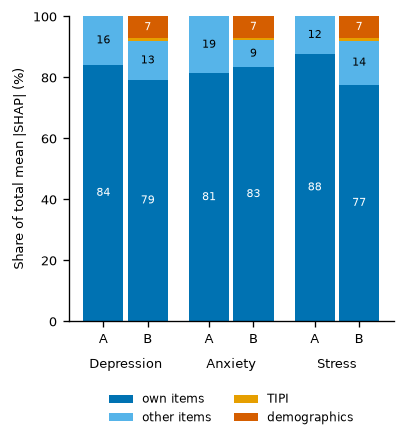

In [42]:
def plot_group_shares(imp_A, imp_B):
    gA = group_summary(imp_A).reindex(columns=GROUPS, fill_value=0)
    gB = group_summary(imp_B, "sum").reindex(columns=GROUPS, fill_value=0)
    fig, ax = plt.subplots(figsize=(3.5, 3.3))
    width, gap = 0.38, 0.04
    xticks, xlabels = [], []
    for k, (g, lab) in enumerate([(gA, "A"), (gB, "B")]):
        x = np.arange(len(SCALES)) + (k - 0.5) * (width + gap)
        bottom = np.zeros(len(SCALES))
        for grp in GROUPS:
            vals = g.loc[SCALES, grp].values
            ax.bar(x, vals, width, bottom=bottom, color=GROUP_COLORS[grp],
                   label=grp if k == 0 else None)
            for xi, v, b in zip(x, vals, bottom):
                if v >= 4:
                    ax.text(xi, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=6.5,
                            color="black" if grp == "other items" else "white")
            bottom += vals
        xticks += list(x); xlabels += [lab] * len(SCALES)
    order = np.argsort(xticks)
    ax.set_xticks(np.array(xticks)[order], np.array(xlabels)[order])
    for i, sc in enumerate(SCALES):
        ax.text(i, -0.12, SCALE_NAMES[sc], transform=ax.get_xaxis_transform(), ha="center", va="top")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Share of total mean |SHAP| (%)")
    ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
    return fig

fig = plot_group_shares(imp_A, imp_B)
save_fig(fig, "fig3_group_shares")
plt.show()

Fig. 4: Top 15 variables per scale

The 15 most important variables per scale in Experiment B, ranked by share of mean |SHAP|, with dummies of nominal variables aggregated per original variable. Three panels (Depression, Anxiety, Stress) show horizontal bars in descending order, coloured by variable group. Each panel has its own x-axis.

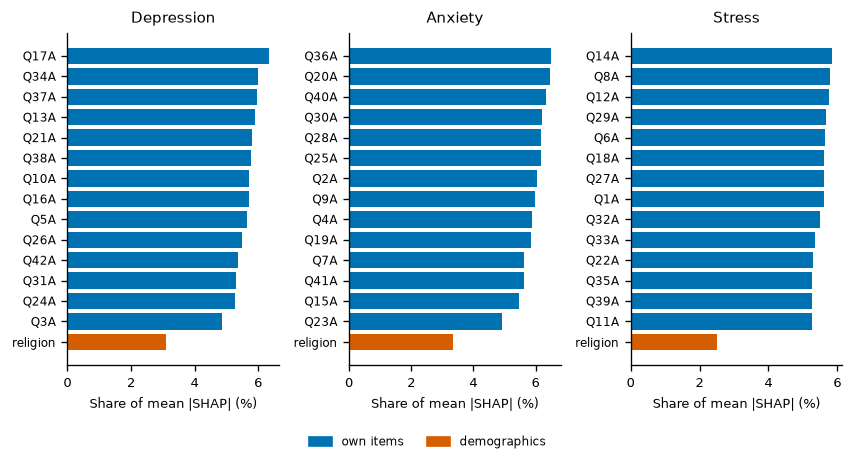

In [43]:
def plot_top_vars(imp, k=15):
    fig, axes = plt.subplots(1, len(SCALES), figsize=(7.16, 3.8))
    present = set()
    for ax, sc in zip(axes, SCALES):
        s = imp[sc].sort_values(ascending=False).head(k)[::-1]      # reversed: top bar on top
        groups = [group_of(v, sc) for v in s.index]
        present |= set(groups)
        ax.barh(s.index, s.values, color=[GROUP_COLORS[g] for g in groups])
        ax.set_title(SCALE_NAMES[sc])
        ax.set_xlabel("Share of mean |SHAP| (%)")
        ax.tick_params(axis="y", labelsize=7)
    fig.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in GROUPS if g in present],
               ncol=4, loc="lower center", frameon=False)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    return fig

fig = plot_top_vars(imp_B)
save_fig(fig, "fig4_top15_B")
plt.show()

# optional: same plot for experiment A
# fig = plot_top_vars(imp_A); save_fig(fig, "fig4_top15_A"); plt.show()

Fig. 5: Effect of religion on Depression

Mean SHAP contribution of religion to each severity class of the Depression head in Experiment B. Rows are religions with at least 100 test samples, sorted by size; columns are severity classes. Values are centred logits: red pushes towards the class, blue away. They are measured relative to a Muslim-dominated background.

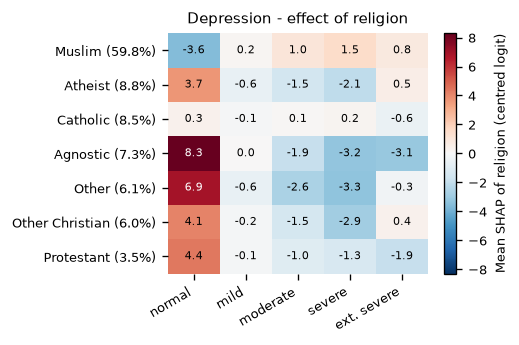

In [55]:
def plot_religion_heatmap(res_rel, min_n=100):
    r = res_rel[res_rel["n"] >= min_n].sort_values("n", ascending=False)
    M = r[LEVELS].values
    total = r["n"].sum()
    vmax = np.abs(M).max()
    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(LEVELS)), LEVELS, rotation=30, ha="right")
    ax.set_yticks(range(len(r)), [f"{REL_NAMES[i]} ({int(n)/total*100:.1f}%)" for i, n in zip(r.index, r["n"])])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(M[i, j]) > 0.6 * vmax else "black")
    for s in ax.spines.values(): s.set_visible(False)
    cb = fig.colorbar(im, ax=ax)
    cb.set_label("Mean SHAP of religion (centred logit)")
    ax.set_title("Depression - effect of religion")
    return fig

fig = plot_religion_heatmap(res)       # `res` = table built in the religion cell
save_fig(fig, "fig5_religion_heatmap")
plt.show()

Fig. 6: SHAP beeswarm - Experiment B, extremely severe Depression

Beeswarm of the fifteen most important variables of the Depression head in Experiment B, explaining the extremely severe class. Each point is one test respondent, positioned by its SHAP value (centred logit) and coloured by feature value, from low (blue) to high (red). Nominal variables are shown in grey.

For each test respondent, SHAP decomposes the logit of the "extremely severe" depression class
into a baseline plus one additive contribution per variable. The beeswarm shows that the 10
depression items contribute with similar magnitude (up to about ±6 logits) and in an ordered way:
high answers push the logit up, low answers push it down.

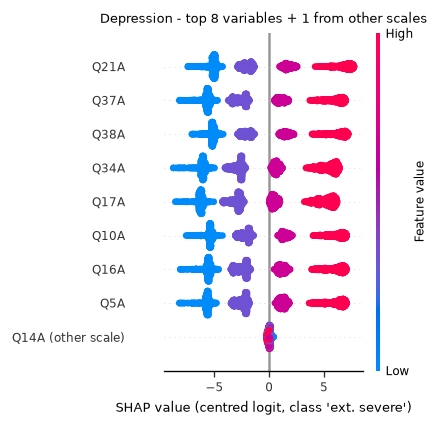

In [63]:
def plot_beeswarm(sv_dict, sub_test, cols, scale="D", cls=4, max_display=8, extra=()):
    """Beeswarm of the top `max_display` variables, plus the variables listed in `extra` (shown at the bottom)."""
    sv = sv_dict[scale]                                    # (n, f, 5)
    sv = sv - sv.mean(axis=2, keepdims=True)               # centre over the 5 classes
    vars_ = np.array([var_of(c) for c in cols])
    names = list(dict.fromkeys(vars_))
    X = np.asarray(sub_test)
    S, F = [], []
    for v in names:
        m = vars_ == v
        S.append(sv[:, m, cls].sum(axis=1))                # SHAP per original variable (dummies summed)
        F.append(X[:, m][:, 0] if m.sum() == 1 else np.full(len(X), np.nan))   # nominal: no colour
    S, F = np.column_stack(S), np.column_stack(F)

    imp = np.abs(S).mean(axis=0)                           # importance on this class, to pick the top rows
    order = [i for i in np.argsort(-imp) if names[i] not in extra][:max_display]
    order += [names.index(v) for v in extra]               # forced rows go last (bottom of the plot)
    labels = [f"{names[i]} (other scale)" if names[i] in extra else names[i] for i in order]

    fig = plt.figure(figsize=(3.8, 3.6))                   # new figure: summary_plot draws on the current one
    shap.summary_plot(S[:, order], F[:, order], feature_names=labels,
                      max_display=len(order), sort=False, plot_size=None, show=False)
    for ax in fig.axes:                                    # shrink shap's default fonts for a paper column
        ax.tick_params(labelsize=7)
    fig.axes[0].set_xlabel(f"SHAP value (centred logit, class '{LEVELS[cls]}')", fontsize=8)
    fig.axes[0].set_title(f"{SCALE_NAMES[scale]} - top {max_display} variables + {len(extra)} from other scales", fontsize=8)
    fig.axes[-1].set_ylabel("Feature value", fontsize=7)
    fig.tight_layout()
    return fig

# one item that do NOT belong to the Depression scale: the top "other items" of the importance ranking
extra = top_non_own(imp_B, "D", k=20).query("group == 'other items'").index[:1].tolist()

fig = plot_beeswarm(shap_B, sub_test_B, X_train.columns, scale="D", cls=4, extra=extra)
save_fig(fig, "fig6_beeswarm_D")
plt.show()

# Utils (not part of the project)

During the development of the project, I needed these utils to speed up the process.


## Store useful data

In [31]:
import torch, numpy as np, os

SAVE_ARTIFACTS = False
ARTIFACT_DIR = "./data"

if SAVE_ARTIFACTS:
    # from google.colab import drive; drive.mount("/content/drive")   # run once per session
    os.makedirs(ARTIFACT_DIR, exist_ok=True)

    torch.save(model_A.state_dict(), f"{ARTIFACT_DIR}/model_A.pt")
    torch.save(model_B.state_dict(), f"{ARTIFACT_DIR}/model_B.pt")

    np.savez_compressed(f"{ARTIFACT_DIR}/shap_A.npz", **shap_A)
    np.savez_compressed(f"{ARTIFACT_DIR}/shap_B.npz", **shap_B)

    torch.save({"Xt_A": Xt_A, "Xte_A": Xte_A, "Xt_B": Xt_B, "Xte_B": Xte_B},
               f"{ARTIFACT_DIR}/data_shap.pt")

## Load useful data

In [32]:
import torch, numpy as np, os

RELOAD_FROM_DISK = False
ARTIFACT_DIR = "./data"

if RELOAD_FROM_DISK:
    # from google.colab import drive; drive.mount("/content/drive")   # run once per session
    os.makedirs(ARTIFACT_DIR, exist_ok=True)

    d = torch.load(f"{ARTIFACT_DIR}/data_shap.pt", weights_only=False)
    Xt_A, Xte_A, Xt_B, Xte_B = d["Xt_A"], d["Xte_A"], d["Xt_B"], d["Xte_B"]

    def load_clean(model, path):
        sd = torch.load(path, map_location="cpu")
        sd = {k: v for k, v in sd.items() if not k.endswith((".x", ".y"))}   # drop shap's leftovers
        model.load_state_dict(sd)          # strict: still errors if real weights are missing
        return model.eval()

    model_A = load_clean(MultiHeadANN(n_features=Xt_A.shape[1]), f"{ARTIFACT_DIR}/model_A.pt")
    model_B = load_clean(MultiHeadANN(n_features=Xt_B.shape[1]), f"{ARTIFACT_DIR}/model_B.pt")

    shap_A = dict(np.load(f"{ARTIFACT_DIR}/shap_A.npz"))
    shap_B = dict(np.load(f"{ARTIFACT_DIR}/shap_B.npz"))